<a href="https://colab.research.google.com/github/msumathi-07/ABSA-BERT-Streamlit-Dashboard/blob/main/Land_Use_and_Land_Cover_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!wget -q -O /content/EuroSAT_RGB.zip \
  "https://zenodo.org/records/7711097/files/EuroSAT_RGB.zip?download=1"

print("Dataset ZIP downloaded!")


Dataset ZIP downloaded!


In [2]:

import os
import zipfile

zip_path = "/content/EuroSAT_RGB.zip"
extract_path = "/content/EuroSAT"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files:", os.listdir(extract_path)[:10])


Dataset extracted successfully!
Files: ['__MACOSX', 'EuroSAT_RGB']


In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [4]:
data_dir = None

for root, dirs, files in os.walk(extract_path):
    expected = {
        "AnnualCrop", "Forest", "Highway",
        "Residential", "River", "SeaLake"
    }

    if expected.issubset(set(dirs)):
        data_dir = root
        break

if data_dir is None:
    raise FileNotFoundError(
        "Class folders not found. Check the extracted folder structure."
    )

print("Dataset location:", data_dir)
print("Classes:", sorted(os.listdir(data_dir)))


Dataset location: /content/EuroSAT/__MACOSX/EuroSAT_RGB
Classes: ['._.DS_Store', '._AnnualCrop', '._Forest', '._HerbaceousVegetation', '._Highway', '._Industrial', '._Pasture', '._PermanentCrop', '._Residential', '._River', '._SeaLake', 'AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [9]:

import os

for root, dirs, files in os.walk("/content/EuroSAT"):
    class_names_found = [
        d for d in dirs
        if d in [
            "AnnualCrop", "Forest", "HerbaceousVegetation",
            "Highway", "Industrial", "Pasture",
            "PermanentCrop", "Residential", "River", "SeaLake"
        ]
    ]

    if len(class_names_found) >= 5:
        data_dir = root
        break

print("Correct dataset folder:", data_dir)
print("Land-cover classes:", sorted(os.listdir(data_dir)))




Correct dataset folder: /content/EuroSAT/__MACOSX/EuroSAT_RGB
Land-cover classes: ['._.DS_Store', '._AnnualCrop', '._Forest', '._HerbaceousVegetation', '._Highway', '._Industrial', '._Pasture', '._PermanentCrop', '._Residential', '._River', '._SeaLake', 'AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [10]:

valid_extensions = (".jpg", ".jpeg", ".png")

for class_name in sorted(os.listdir(data_dir)):
    folder = os.path.join(data_dir, class_name)

    if os.path.isdir(folder):
        count = sum(
            f.lower().endswith(valid_extensions)
            for f in os.listdir(folder)
        )
        print(f"{class_name}: {count} images")


AnnualCrop: 3000 images
Forest: 3000 images
HerbaceousVegetation: 3000 images
Highway: 2500 images
Industrial: 2500 images
Pasture: 2000 images
PermanentCrop: 2500 images
Residential: 3000 images
River: 2500 images
SeaLake: 3000 images


In [12]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

# Split the held-out 20% equally into validation and testing
temp_batches = tf.data.experimental.cardinality(temp_ds).numpy()
val_batches = temp_batches // 2

val_ds = temp_ds.take(val_batches)
test_ds = temp_ds.skip(val_batches)

# Improve input pipeline performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Classes:", class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 27000 files belonging to 10 classes.
Using 21600 files for training.
Found 27000 files belonging to 10 classes.
Using 5400 files for validation.
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Training batches: 675
Validation batches: 84
Test batches: 85


In [15]:

import os

# Find the actual EuroSAT class folders
data_dir = "/content/EuroSAT/EuroSAT_RGB"

print("Dataset folder exists:", os.path.isdir(data_dir))
print("Classes:", os.listdir(data_dir)[:15])



Dataset folder exists: True
Classes: ['PermanentCrop', 'HerbaceousVegetation', 'Industrial', 'AnnualCrop', 'Residential', 'SeaLake', 'River', '.DS_Store', 'Highway', 'Pasture', 'Forest']


In [16]:

import tensorflow as tf

IMG_SIZE = (64, 64)
BATCH_SIZE = 32
SEED = 42

# Build a clean image dataset from the class folders
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
)

class_names = train_ds.class_names

# Split validation subset into validation and test sets
val_batches = tf.data.experimental.cardinality(temp_ds).numpy() // 2
val_ds = temp_ds.take(val_batches)
test_ds = temp_ds.skip(val_batches)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Classes:", class_names)


Found 27000 files belonging to 10 classes.
Using 21600 files for training.
Found 27000 files belonging to 10 classes.
Using 5400 files for validation.
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [17]:

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)


Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)


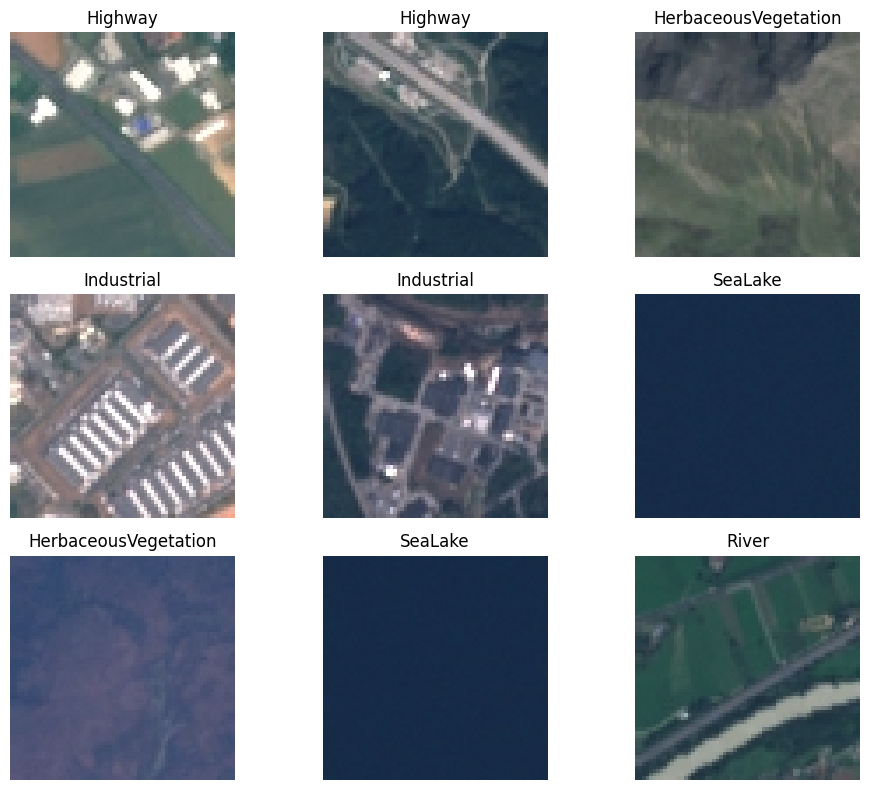

In [18]:

import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 8))

    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [19]:

import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),

    # Normalize image pixel values
    tf.keras.layers.Rescaling(1./255),

    # Convolutional layers learn image features
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)


Epoch 1/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 197s 289ms/step - accuracy: 0.5128 - loss: 1.3048 - val_accuracy: 0.6421 - val_loss: 0.9592
Epoch 2/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 207s 297ms/step - accuracy: 0.6996 - loss: 0.8432 - val_accuracy: 0.7303 - val_loss: 0.7396
Epoch 3/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 200s 293ms/step - accuracy: 0.7586 - loss: 0.6846 - val_accuracy: 0.8121 - val_loss: 0.5477
Epoch 4/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 193s 280ms/step - accuracy: 0.7949 - loss: 0.5835 - val_accuracy: 0.8281 - val_loss: 0.4923
Epoch 5/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 209s 309ms/step - accuracy: 0.8209 - loss: 0.5160 - val_accuracy: 0.8557 - val_loss: 0.4398
Epoch 6/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 201s 297ms/step - accuracy: 0.8434 - loss: 0.4419 - val_accuracy: 0.8746 - val_loss: 0.3872
Epoch 7/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 199s 293ms/step - accuracy: 0.8651 - loss: 0.3880 - val_accuracy: 0.8679 - val_loss: 0.3953
Epoch 8/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 201s 298ms/step - accuracy: 0.8818 -

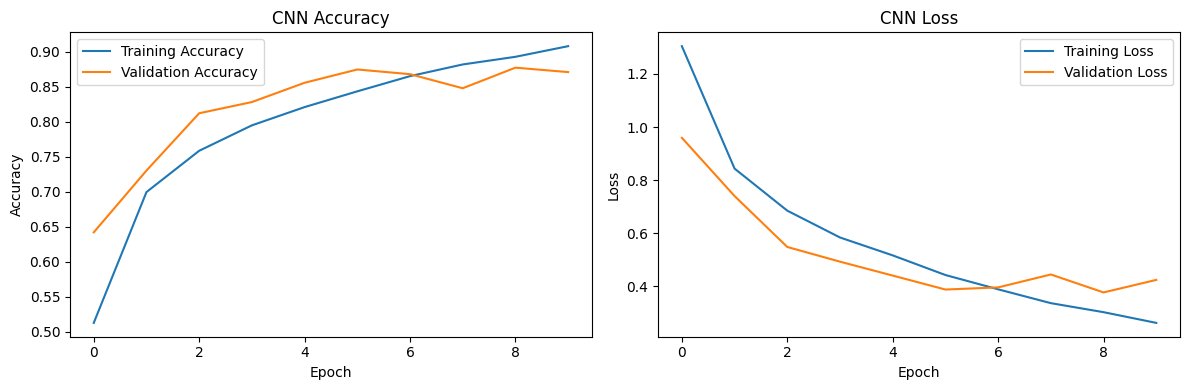

In [21]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [22]:

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 87ms/step - accuracy: 0.8603 - loss: 0.4571
Test Loss: 0.4571
Test Accuracy: 86.03%
